# DAY5 실습 03 — 상관행렬과 히트맵

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 데이터와 질문

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

한 행은 **운전 기록 1건**이다. 같은 행에 적힌 두 측정값을 **관측쌍** 하나로 본다.

| 원래 열 이름 | 바꾼 이름 | 뜻 | 단위 |
|---|---|---|---|
| Air temperature [K] | `air_temperature_k` | 공기온도 | K (켈빈) |
| Process temperature [K] | `process_temperature_k` | 공정온도 | K |
| Rotational speed [rpm] | `rotational_speed_rpm` | 회전수 | rpm (분당 회전수) |
| Torque [Nm] | `torque_nm` | 토크 | Nm (뉴턴미터) |
| Tool wear [min] | `tool_wear_min` | 공구 마모시간 | 분 |
| Type | `Type` (그대로) | 제품 유형 (L : 저품질, M : 중품질, H : 고품질) | 없음 |

**질문** : 측정 변수가 여러 개일 때, 어느 변수쌍부터 자세히 볼 것인가?

**실습 전제** : AI4I는 제조 예지보전을 학습하도록 만든 합성 데이터다. 관측쌍끼리 서로 독립이라고 가정한다.

In [ ]:
raw = data.rename(columns={"Air temperature [K]": "air_temperature_k",       # 공기온도 (K)
                           "Process temperature [K]": "process_temperature_k",  # 공정온도 (K)
                           "Rotational speed [rpm]": "rotational_speed_rpm",    # 회전수 (rpm)
                           "Torque [Nm]": "torque_nm",                          # 토크 (Nm)
                           "Tool wear [min]": "tool_wear_min"})                 # 공구 마모시간 (분)

numeric_cols = ["air_temperature_k", "process_temperature_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]
print("행·열:", raw.shape)
print(raw[numeric_cols].isna().sum())        # 열마다 결측(빈 값) 개수. 상관은 같은 행의 두 값으로 계산하므로 먼저 확인한다

행·열: (10000, 14)
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
dtype: int64


## 1. 상관행렬 : 모든 변수쌍의 상관계수를 표 하나에

변수가 늘면 확인할 쌍은 훨씬 빨리 는다. **변수쌍 수 = 변수 개수 × (변수 개수 − 1) ÷ 2** 이다. 변수 5개면 10쌍, 10개면 45쌍, 20개면 190쌍이다. 산점도를 한 장씩 다 그려서는 감당이 안 되므로, 상관계수를 모두 보고 먼저 확인할 변수를 고른다。
**상관행렬**은 변수를 가로와 세로에 같은 순서로 놓고, 각 칸에 그 두 변수의 상관계수를 적은 표다.

| 읽는 법 | 내용 |
|---|---|
| 대각선 | 자기 자신과의 상관이라 항상 1이다. 읽지 않는다 |
| 대칭 | 가로세로를 바꿔도 같은 값이다. 절반만 읽는다 |
| 절댓값이 큰 칸부터 | 부호로 방향, 절댓값으로 강도를 보고 볼 쌍을 고른다 |
| 한계 | 관계의 모양(곡선 · 군집)과 이상값은 알려 주지 않는다 → 고른 쌍은 산점도로 다시 본다 |

| 함수 | 기능 |
|---|---|
| `raw[numeric_cols].corr(method="pearson")` | 피어슨 상관행렬. method 를 적지 않아도 기본이 피어슨이다 |
| `raw[numeric_cols].corr(method="spearman")` | 스피어만 상관행렬 |

공식 문서 : [pandas.DataFrame.corr](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)

In [ ]:
# [예제] 다섯 측정 변수의 피어슨 상관행렬을 만든다
k = len(numeric_cols)
print("변수 개수:", k, "/ 변수쌍 수:", k * (k - 1) // 2)       # // : 나눗셈의 몫(정수)

pearson_matrix = raw[numeric_cols].corr(method="pearson")
display(pearson_matrix.round(3))

# [결과]
# - 변수 5개 → 10쌍. 표는 5 × 5 = 25칸이지만 대각선 5칸을 빼고 대칭이라 실제로 읽을 칸은 10칸이다
# - 절댓값이 큰 칸
# - 공기온도 · 공정온도 : r = 0.876 → 강한 양의 선형 관계.
#   공기온도가 높을수록 공정온도도 높아지는 경향이 있다.
# - 회전수 · 토크 : r = -0.875 → 강한 음의 선형 관계.
#   회전수가 높을수록 토크는 낮아지는 경향이 있다.
# - 공구마모와 다른 변수들 : r이 0에 가까움 → 뚜렷한 선형 관계가 나타나지 않는다.

변수 개수: 5 / 변수쌍 수: 10


,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
air_temperature_k,1.000,0.876,0.023,-0.014,0.014
process_temperature_k,0.876,1.000,0.019,-0.014,0.013
rotational_speed_rpm,0.023,0.019,1.000,-0.875,0.000
torque_nm,-0.014,-0.014,-0.875,1.000,-0.003
tool_wear_min,0.014,0.013,0.000,-0.003,1.000


## 2. 히트맵 : 상관행렬을 색으로

**히트맵**은 행렬의 값을 색으로 칠한 그림이다. 숫자를 하나씩 읽지 않아도 진한 칸이 먼저 보인다. 색 범위를 −1 ~ 1로 고정해야 그림끼리 비교할 수 있다.

| 색 (coolwarm) | 뜻 |
|---|---|
| 붉을수록 | 양의 상관 |
| 푸를수록 | 음의 상관 |
| 옅은 회색 | 0 근처 |

색이 진해도 관계의 모양은 알 수 없다.

| 함수 | 기능 |
|---|---|
| `plt.imshow(행렬, vmin=-1, vmax=1, cmap="coolwarm")` | 행렬을 색으로 칠한다. vmin · vmax 는 색 범위, cmap 은 색 지도 |
| `plt.colorbar(그림, label="이름")` | 색과 값을 잇는 눈금 막대를 붙인다 |
| `plt.xticks(위치, 이름)` · `plt.yticks(위치, 이름)` | 칸 위치마다 변수 이름을 붙인다 |
| `plt.text(x, y, 글자)` | 그림의 (x, y) 위치에 글자를 쓴다 |

공식 문서 : [matplotlib.pyplot.imshow](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) · [matplotlib.pyplot.colorbar](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html)

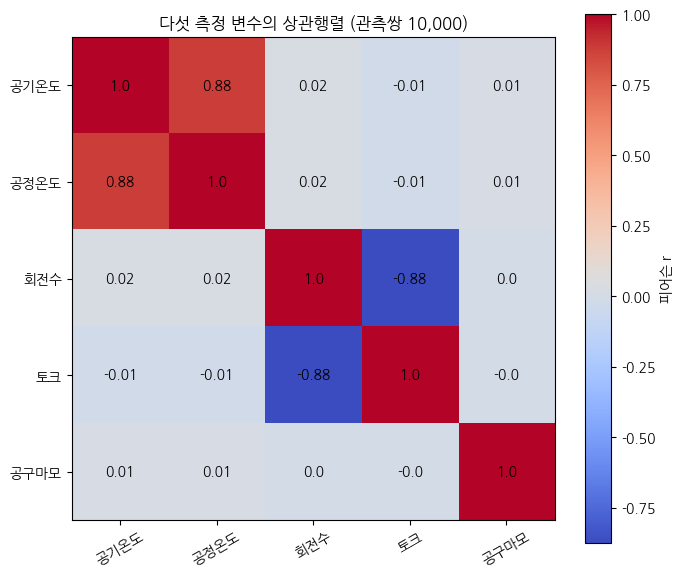

In [ ]:
# [예제]
labels = ["공기온도", "공정온도", "회전수", "토크", "공구마모"]      # numeric_cols 와 같은 순서

plt.figure(figsize=(7, 6))
image = plt.imshow(pearson_matrix,  cmap="coolwarm")
plt.colorbar(image, label="피어슨 r")
plt.xticks(range(5), labels, rotation=30)     # range(5) : 0 ~ 4 번 칸 위치, rotation=30 : 글자를 30도 기울인다
plt.yticks(range(5), labels)
for i in range(5):                            # i : 행 번호, j : 열 번호
    for j in range(5):
        plt.text(j, i, round(pearson_matrix.iloc[i, j], 2), ha="center", va="center")   # iloc[행, 열] : 위치로 값 꺼내기, ha · va : 가운데 정렬
plt.title("다섯 측정 변수의 상관행렬 (관측쌍 10,000)")
plt.tight_layout()
plt.show()

# [결과]
# - 대각선은 진한 빨강(1), 공기온도 · 공정온도 칸은 빨강(0.88), 회전수 · 토크 칸은 파랑(−0.88)
# - 나머지 칸은 흰색에 가깝다(r ≈ 0) －＞ 뚜렷한 선형 관계가 없다.
# - 대각선을 기준으로 위아래가 같은 색이다(대칭)


## 3. 상관행렬에서 확인한 주요 변수 쌍의 산점도 분석
상관행렬을 통해 주요 변수 쌍을 선정하고, 산점도를 이용해 관계의 형태, 군집 및 이상값을 시각적으로 확인한다. 분석의 일관성을 위해 상관계수와 산점도는 동일한 관측쌍을 사용한다.

관측쌍: 10000 / 행렬의 r: -0.875


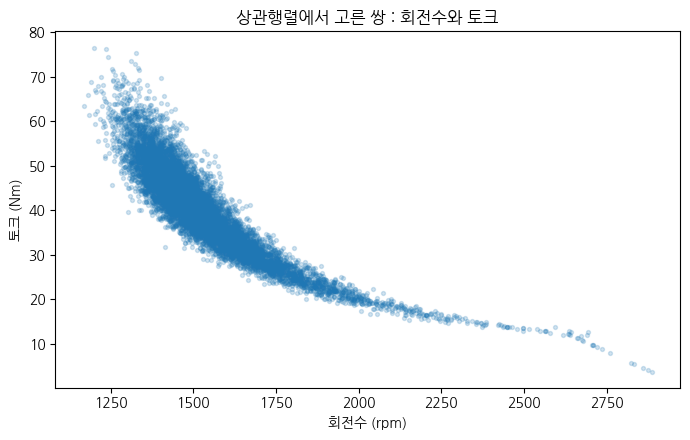

In [ ]:
# [예제] 상관행렬에서 고른 회전수 · 토크 쌍을 산점도로 다시 본다

speed_pair = raw[["rotational_speed_rpm", "torque_nm"]].dropna()
speed = speed_pair["rotational_speed_rpm"]
torque = speed_pair["torque_nm"]
print("관측쌍:", len(speed_pair), "/ 행렬의 r:", round(pearson_matrix.loc["rotational_speed_rpm", "torque_nm"], 3))
#   pearson_matrix.loc[행 이름, 열 이름] : 이름으로 칸 하나를 꺼낸다

plt.figure(figsize=(7, 4.5))
plt.scatter(speed, torque, s=8, alpha=0.2)
plt.xlabel("회전수 (rpm)")
plt.ylabel("토크 (Nm)")
plt.title("상관행렬에서 고른 쌍 : 회전수와 토크")
plt.tight_layout()
plt.show()

# [결과]
# - 행렬의 칸은 r = −0.875 하나지만, 산점도는 직선이 아니라 휜 곡선이다
# - 숫자만 보면 놓치는 모양이다. 그래서 고른 쌍은 산점도로 확인하고 스피어만도 함께 본다

In [ ]:
# [실습]
# 상황 : 1절의 피어슨 상관행렬(pearson_matrix)은 직선 관계로 나타내고. 직선은 아니지만 한 방향으로 움직이는 쌍이 있는지 스피어만 상관행렬로 함께 확인한다.
# 다섯 측정 변수의 스피어만 상관행렬을 구하고, 칸마다 |스피어만| − |피어슨|을 계산해 차이가 가장 큰 쌍을 찾으시오.

spearman_matrix = raw[numeric_cols].corr(method="spearman")
display(spearman_matrix.round(3))
print("|스피어만| − |피어슨| :")
display((spearman_matrix.abs() - pearson_matrix.abs()).round(3))


# [결과]
# - 회전수 · 토크 : 스피어만 -0.916, 피어슨 -0.875 → +0.041
#   순위를 이용한 스피어만 상관계수에서 더 강한 음의 관계가 나타난다.
#   관계가 곡선 형태인지, 이상값의 영향이 있는지는 산점도로 확인한다.
#
# - 공기온도 · 공정온도 : 스피어만 0.864, 피어슨 0.876 → -0.012
#   두 상관계수가 비슷하며, 강한 양의 관계를 나타낸다.
#
# - 차이가 양수이면 스피어만의 절댓값이 더 크고,
#   음수이면 피어슨의 절댓값이 더 크다.


,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
air_temperature_k,1.000,0.864,0.014,-0.012,0.013
process_temperature_k,0.864,1.000,0.017,-0.014,0.014
rotational_speed_rpm,0.014,0.017,1.000,-0.916,0.003
torque_nm,-0.012,-0.014,-0.916,1.000,-0.004
tool_wear_min,0.013,0.014,0.003,-0.004,1.000


|스피어만| − |피어슨| :


,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
air_temperature_k,0.000,-0.012,-0.009,-0.002,-0.000
process_temperature_k,-0.012,0.000,-0.002,0.000,0.000
rotational_speed_rpm,-0.009,-0.002,0.000,0.041,0.003
torque_nm,-0.002,0.000,0.041,0.000,0.001
tool_wear_min,-0.000,0.000,0.003,0.001,0.000


## 4. 정리 : 상관행렬과 히트맵

| 순서 | 할 일 | 코드 |
|---|---|---|
| 1) | 측정 변수 목록으로 피어슨 상관행렬을 만든다 | `raw[numeric_cols].corr(method="pearson")` |
| 2) | 히트맵으로 진한 칸을 찾는다 | `plt.imshow(행렬, vmin=-1, vmax=1, cmap="coolwarm")` |
| 3) | 고른 쌍은 산점도로 모양 · 군집 · 이상값을 확인한다 | `plt.scatter(x, y)` |
| 4) | 휜 쌍이 의심되면 스피어만 행렬과 비교한다 | `raw[numeric_cols].corr(method="spearman")` |

### 해석 시 유의점

- 상관행렬: 여러 변수의 상관계수를 비교해 주요 변수 쌍을 선정한다. 관계의 형태, 군집 및 이상값은 산점도로 확인한다.

- 대각선과 대칭성: 대각선은 자기 자신과의 상관계수이므로 1이다. 상관행렬은 대칭이므로 대각선을 제외한 한쪽 절반만 확인하면 된다.

- 히트맵: 색상 범위를 −1~+1로 고정하여 관계의 방향과 강도를 비교한다. 색상만으로 관계의 형태나 이상값은 판단할 수 없다.

- 피어슨과 스피어만: 피어슨은 선형 관계, 스피어만은 단조 관계를 확인한다. 두 값의 차이가 크다면 산점도로 관계의 형태와 이상값의 영향을 살펴본다.

- 상관관계와 인과관계: 상관계수가 높더라도 한 변수가 다른 변수의 변화를 일으킨다고 단정할 수 없다.